#Task 1

In [ ]:
# ── STEP 0: Mount Google Drive ────────────────────────────────────────────────
from google.colab import drive
drive.mount("/content/drive")

import os
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for f in files:
        if "filtered_feature_bc_matrix" in f or "metadata.tsv" in f:
            print(os.path.join(root, f))

Mounted at /content/drive
/content/drive/MyDrive/28200299/51654962_filtered_feature_bc_matrix.h5
/content/drive/MyDrive/28200299/51654968_filtered_feature_bc_matrix.h5
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151507/filtered_feature_bc_matrix.h5
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151507/151507_filtered_feature_bc_matrix.h5
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151507/metadata.tsv
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151670/metadata.tsv
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151510/filtered_feature_bc_matrix.h5
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151510/metadata.tsv
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151509/metadata.tsv
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151509/filtered_feature_bc_matrix.h5
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151509/151509_filtered_feature_bc_matrix.h5
/content/drive/MyDrive/28200299/10X Visium/DLPFC/151669/metadata.tsv
/content/drive/MyDrive/28200299/10X Visium/

In [ ]:
!pip install scanpy
import scanpy as sc
import pandas as pd
import numpy as np
import json
import os
import matplotlib.image as mpimg

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.4/174.4 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.6/319.6 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 76.7 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2

In [ ]:



DATA_DIR     = "/content/drive/MyDrive/visium_sample"
H5_PATH      = os.path.join(DATA_DIR, "filtered_feature_bc_matrix.h5")
META_PATH    = os.path.join(DATA_DIR, "metadata.tsv")
SPATIAL_DIR  = os.path.join(DATA_DIR, "spatial")
PROCESSED_H5 = os.path.join(DATA_DIR, "151671_visium_processed.h5ad")

for label, path in [("H5",          H5_PATH),
                    ("Metadata",     META_PATH),
                    ("Spatial dir",  SPATIAL_DIR),
                    ("Processed h5", PROCESSED_H5)]:
    print(f"{label:14s} {'✓ found' if os.path.exists(path) else '✗ MISSING'}  →  {path}")

# ─────────────────────────────────────────────
# STEP 1 – Read raw gene expression (.h5)
# ─────────────────────────────────────────────
adata = sc.read_10x_h5(H5_PATH)
adata.var_names_make_unique()

print("\nAfter reading .h5:")
print(f"  Spots : {adata.n_obs}")
print(f"  Genes : {adata.n_vars}")

# ─────────────────────────────────────────────
# STEP 2 – Add spatial coordinates
# ─────────────────────────────────────────────
positions = pd.read_csv(
    os.path.join(SPATIAL_DIR, "tissue_positions_list.csv"),
    header=None,
    names=["barcode", "in_tissue", "array_row", "array_col",
           "pxl_row_in_fullres", "pxl_col_in_fullres"],
    index_col=0,
)

positions = positions[positions["in_tissue"] == 1]

adata = adata[adata.obs_names.isin(positions.index)].copy()
positions = positions.loc[adata.obs_names]

adata.obsm["spatial"] = positions[
    ["pxl_col_in_fullres", "pxl_row_in_fullres"]
].values.astype(float)

adata.obs["array_row"] = positions["array_row"].values
adata.obs["array_col"] = positions["array_col"].values

print(f"\nobsm['spatial'] shape : {adata.obsm['spatial'].shape}")

# ─────────────────────────────────────────────
# STEP 3 – Add scale factors + tissue image
# ─────────────────────────────────────────────
with open(os.path.join(SPATIAL_DIR, "scalefactors_json.json")) as f:
    scalefactors = json.load(f)

lowres_img = mpimg.imread(
    os.path.join(SPATIAL_DIR, "tissue_lowres_image.png")
)

library_id = "151671"
adata.uns["spatial"] = {
    library_id: {
        "images"      : {"lowres": lowres_img},
        "scalefactors": scalefactors,
    }
}

print(f"Tissue image shape    : {lowres_img.shape}")
print(f"Scale factors         : {scalefactors}")

# ─────────────────────────────────────────────
# STEP 4 – Add ground-truth layer annotations
# ─────────────────────────────────────────────
metadata = pd.read_csv(META_PATH, sep="\t", index_col=0)

print("\nMetadata columns :", metadata.columns.tolist())
print("Unique layers    :", metadata["layer_guess_reordered"].unique())

metadata = metadata.reindex(adata.obs_names)
adata.obs["layer_guess_reordered"] = (
    metadata["layer_guess_reordered"].astype("category").values
)

print("\nLayer distribution:")
print(adata.obs["layer_guess_reordered"].value_counts())

# ─────────────────────────────────────────────
# STEP 5 – Sanity checks
# ─────────────────────────────────────────────
assert adata.obsm["spatial"].shape[1] == 2,          "Spatial coords must be 2-D"
assert "layer_guess_reordered" in adata.obs.columns,  "Layer column missing"
assert adata.obs["layer_guess_reordered"].notna().any(),"No valid layer annotations"

print("\n✓ All sanity checks passed")
print(adata)

# ─────────────────────────────────────────────
# STEP 6 – Save assembled object
# ─────────────────────────────────────────────
OUT_PATH = "/content/drive/MyDrive/visium_sample/151671_my_assembled.h5ad"
adata.write_h5ad(OUT_PATH)
print(f"\nSaved → {OUT_PATH}")

# ─────────────────────────────────────────────
# STEP 7 – Validate against processed reference
# ─────────────────────────────────────────────
ref = sc.read_h5ad(PROCESSED_H5)
print("=== Reference object ===")
print(ref)

print(f"\nOur spots : {adata.n_obs}  |  Reference spots : {ref.n_obs}")

shared = sorted(set(adata.obs_names) & set(ref.obs_names))
print(f"Shared barcodes : {len(shared)} / {ref.n_obs}")

print(f"\nReference obs columns : {ref.obs.columns.tolist()}")

ref_labels = ref[shared].obs["annotation"].astype(str).values
our_labels = adata[shared].obs["layer_guess_reordered"].astype(str).values

match_pct = (ref_labels == our_labels).mean() * 100
print(f"Layer label match : {match_pct:.1f} %")

if match_pct < 100.0:
    comparison = pd.DataFrame({
        "reference_annotation"    : ref[shared].obs["annotation"].values,
        "our_layer_guess_reordered": adata[shared].obs["layer_guess_reordered"].values,
    }, index=shared)

    mismatches = comparison[
        comparison["reference_annotation"].astype(str) !=
        comparison["our_layer_guess_reordered"].astype(str)
    ]
    print(f"\n⚠ {len(mismatches)} spots differ. First 10:")
    print(mismatches.head(10))

    print("\nReference label counts:")
    print(comparison["reference_annotation"].value_counts())
    print("\nOur label counts:")
    print(comparison["our_layer_guess_reordered"].value_counts())
else:
    print("\n✅ Annotations perfectly match the reference.")

H5             ✓ found  →  /content/drive/MyDrive/visium_sample/filtered_feature_bc_matrix.h5
Metadata       ✓ found  →  /content/drive/MyDrive/visium_sample/metadata.tsv
Spatial dir    ✓ found  →  /content/drive/MyDrive/visium_sample/spatial
Processed h5   ✓ found  →  /content/drive/MyDrive/visium_sample/151671_visium_processed.h5ad


/usr/local/lib/python3.12/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")



After reading .h5:
  Spots : 4110
  Genes : 33538

obsm['spatial'] shape : (4110, 2)
Tissue image shape    : (600, 600, 3)
Scale factors         : {'spot_diameter_fullres': 96.38644715313141, 'tissue_hires_scalef': 0.150015, 'fiducial_diameter_fullres': 144.5796707296971, 'tissue_lowres_scalef': 0.045004502}

Metadata columns : ['barcode', 'sample_name', 'tissue', 'row', 'col', 'imagerow', 'imagecol', 'Cluster', 'height', 'width', 'sum_umi', 'sum_gene', 'subject', 'position', 'replicate', 'subject_position', 'discard', 'key', 'cell_count', 'SNN_k50_k4', 'SNN_k50_k5', 'SNN_k50_k6', 'SNN_k50_k7', 'SNN_k50_k8', 'SNN_k50_k9', 'SNN_k50_k10', 'SNN_k50_k11', 'SNN_k50_k12', 'SNN_k50_k13', 'SNN_k50_k14', 'SNN_k50_k15', 'SNN_k50_k16', 'SNN_k50_k17', 'SNN_k50_k18', 'SNN_k50_k19', 'SNN_k50_k20', 'SNN_k50_k21', 'SNN_k50_k22', 'SNN_k50_k23', 'SNN_k50_k24', 'SNN_k50_k25', 'SNN_k50_k26', 'SNN_k50_k27', 'SNN_k50_k28', 'GraphBased', 'Maynard', 'Martinowich', 'Layer', 'layer_guess', 'layer_guess_reorder

#Task 2

In [ ]:

!pip install leidenalg python-igraph
!pip install scikit-misc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 90.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.0/183.0 kB 4.0 MB/s eta 0:00:00


In [ ]:
!pip install -q leidenalg python-igraph scikit-misc squidpy

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.9/193.9 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.9/61.9 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.2/199.2 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.6/51.6 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.

Spots after dropping unlabelled: 4093
AnnData object with n_obs × n_vars = 4093 × 33538
    obs: 'array_row', 'array_col', 'layer_guess_reordered'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


/usr/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)



Option 1 — PCA → Leiden  |  ARI: 0.4832  NMI: 0.4810

Highly variable genes selected: 3000


/usr/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Option 2 — HVG → Leiden  |  ARI: 0.3421  NMI: 0.4316

=== Metrics Summary ===
                        Method    ARI    NMI
                  PCA → Leiden 0.4832 0.4810
HVG (Seurat v3, 3000) → Leiden 0.3421 0.4316


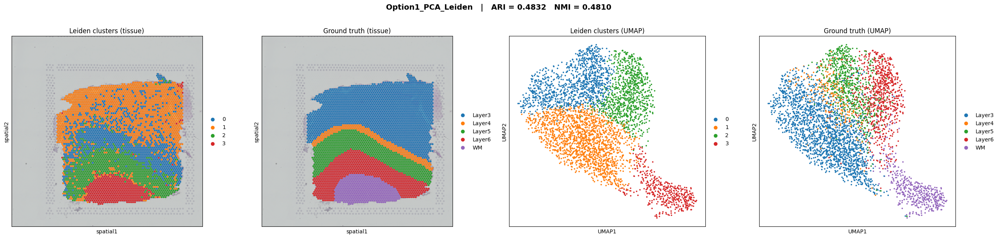

Saved → /content/drive/MyDrive/visium_sample/Option1_PCA_Leiden.png


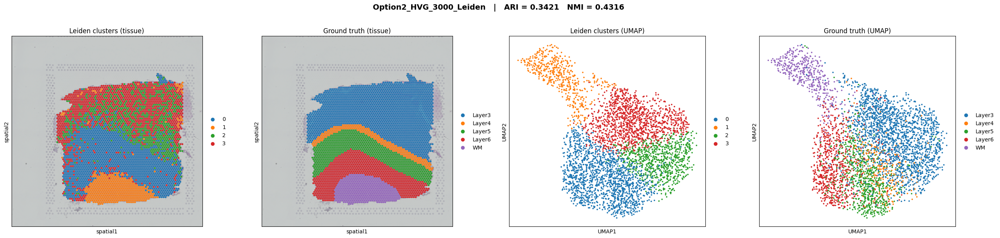

Saved → /content/drive/MyDrive/visium_sample/Option2_HVG_3000_Leiden.png


In [ ]:
"""
Task 2 — CORRECTED: Clustering & Visualization
Fixes: ARI bug, Seurat v3 on raw counts, image re-attachment, leiden flavor
"""


import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import json
import os
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score


SPATIAL_DIR = "/content/drive/MyDrive/visium_sample/spatial"
LIBRARY_ID  = "151671"

hires_img = mpimg.imread(os.path.join(SPATIAL_DIR, "tissue_hires_image.png"))
with open(os.path.join(SPATIAL_DIR, "scalefactors_json.json")) as f:
    scalefactors = json.load(f)


def attach_image(ad, library_id, hires_img, scalefactors):
    """Re-attach hires image and scalefactors after copy() or read_h5ad()."""
    if "spatial" not in ad.uns:
        ad.uns["spatial"] = {}
    if library_id not in ad.uns["spatial"]:
        ad.uns["spatial"][library_id] = {"images": {}, "scalefactors": {}}
    ad.uns["spatial"][library_id]["images"]["hires"] = hires_img
    ad.uns["spatial"][library_id]["scalefactors"]    = scalefactors


adata_raw = sc.read_h5ad(
    "/content/drive/MyDrive/visium_sample/151671_my_assembled.h5ad"
)
attach_image(adata_raw, LIBRARY_ID, hires_img, scalefactors)

adata_raw = adata_raw[adata_raw.obs["layer_guess_reordered"].notna()].copy()
print(f"Spots after dropping unlabelled: {adata_raw.n_obs}")
print(adata_raw)

# ══════════════════════════════════════════════════════════════════
# Pipeline: normalize → log1p → scale → PCA → neighbors → Leiden
# ══════════════════════════════════════════════════════════════════
adata_pca = adata_raw.copy()
attach_image(adata_pca, LIBRARY_ID, hires_img, scalefactors)   # FIX 3 & 4

sc.pp.normalize_total(adata_pca, target_sum=1e4)
sc.pp.log1p(adata_pca)
adata_pca.layers["log1p"] = adata_pca.X.copy()   # save for spatial plotting

sc.pp.scale(adata_pca, max_value=10)
sc.tl.pca(adata_pca, n_comps=50)
sc.pp.neighbors(adata_pca, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_pca)
sc.tl.leiden(                                      # FIX 6
    adata_pca, resolution=0.5,
    key_added="leiden_pca",
    flavor="igraph", n_iterations=2, directed=False
)

true_pca = adata_pca.obs["layer_guess_reordered"].astype(str).values
pred_pca = adata_pca.obs["leiden_pca"].astype(str).values
ari_pca  = adjusted_rand_score(true_pca, pred_pca)
nmi_pca  = normalized_mutual_info_score(true_pca, pred_pca)
print(f"\nOption 1 — PCA → Leiden  |  ARI: {ari_pca:.4f}  NMI: {nmi_pca:.4f}")

# ══════════════════════════════════════════════════════════════════
# OPTION 2 — Seurat v3 HVG (3000 genes) → Leiden
# ══════════════════════════════════════════════════════════════════
adata_hvg = adata_raw.copy()                       # raw counts here
attach_image(adata_hvg, LIBRARY_ID, hires_img, scalefactors)   # FIX 3 & 4

sc.pp.highly_variable_genes(
    adata_hvg,
    n_top_genes=3000,
    flavor="seurat_v3",   # needs integer raw counts
    subset=True           # keep only HVGs
)
print(f"\nHighly variable genes selected: {adata_hvg.n_vars}")

sc.pp.normalize_total(adata_hvg, target_sum=1e4)
sc.pp.log1p(adata_hvg)
adata_hvg.layers["log1p"] = adata_hvg.X.copy()   # save for spatial plotting

sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50)
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_hvg)
sc.tl.leiden(                                      # FIX 6
    adata_hvg, resolution=0.5,
    key_added="leiden_hvg",
    flavor="igraph", n_iterations=2, directed=False
)

true_hvg = adata_hvg.obs["layer_guess_reordered"].astype(str).values
pred_hvg = adata_hvg.obs["leiden_hvg"].astype(str).values
ari_hvg  = adjusted_rand_score(true_hvg, pred_hvg)
nmi_hvg  = normalized_mutual_info_score(true_hvg, pred_hvg)
print(f"Option 2 — HVG → Leiden  |  ARI: {ari_hvg:.4f}  NMI: {nmi_hvg:.4f}")


summary = pd.DataFrame({
    "Method" : ["PCA → Leiden", "HVG (Seurat v3, 3000) → Leiden"],
    "ARI"    : [round(ari_pca, 4), round(ari_hvg, 4)],   # FIX 1
    "NMI"    : [round(nmi_pca, 4), round(nmi_hvg, 4)],
})
print("\n=== Metrics Summary ===")
print(summary.to_string(index=False))


def plot_option(ad, cluster_key, label, ari, nmi, save_dir):
    fig, axes = plt.subplots(1, 4, figsize=(26, 6))
    fig.suptitle(
        f"{label}   |   ARI = {ari:.4f}   NMI = {nmi:.4f}",
        fontsize=14, fontweight="bold", y=1.02
    )

    sq.pl.spatial_scatter(
        ad, color=cluster_key,
        library_id=LIBRARY_ID,
        img=True, img_alpha=0.7,
        size=1.3, ax=axes[0],       # ← remove show=False here
        title="Leiden clusters (tissue)"
    )

    sq.pl.spatial_scatter(
        ad, color="layer_guess_reordered",
        library_id=LIBRARY_ID,
        img=True, img_alpha=0.7,
        size=1.3, ax=axes[1],       # ← remove show=False here
        title="Ground truth (tissue)"
    )

    sc.pl.umap(
        ad, color=cluster_key,
        ax=axes[2], show=False,
        title="Leiden clusters (UMAP)"
    )

    sc.pl.umap(
        ad, color="layer_guess_reordered",
        ax=axes[3], show=False,
        title="Ground truth (UMAP)"
    )

    plt.tight_layout()
    save_path = os.path.join(save_dir, f"{label}.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved → {save_path}")


SAVE_DIR = "/content/drive/MyDrive/visium_sample"

plt.ioff()   # prevent squidpy from auto-showing mid-function
plot_option(adata_pca, "leiden_pca", "Option1_PCA_Leiden",      ari_pca, nmi_pca, SAVE_DIR)
plot_option(adata_hvg, "leiden_hvg", "Option2_HVG_3000_Leiden", ari_hvg, nmi_hvg, SAVE_DIR)
plt.ion()

In [ ]:
# import scanpy as sc
# import pandas as pd
# import numpy as np
# import json
# import os
# import matplotlib.image as mpimg
# import matplotlib.pyplot as plt
# from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score



# # ─────────────────────────────────────────────
# # LOAD THE ASSEMBLED OBJECT
# # ─────────────────────────────────────────────
# adata = sc.read_h5ad("/content/drive/MyDrive/visium_sample/151671_my_assembled.h5ad")

# # Re-attach hires image (not saved in h5ad by default)
# SPATIAL_DIR = "/content/drive/MyDrive/visium_sample/spatial"
# hires_img   = mpimg.imread(os.path.join(SPATIAL_DIR, "tissue_hires_image.png"))

# with open(os.path.join(SPATIAL_DIR, "scalefactors_json.json")) as f:
#     scalefactors = json.load(f)

# adata.uns["spatial"]["151671"]["images"]["hires"]      = hires_img
# adata.uns["spatial"]["151671"]["scalefactors"]         = scalefactors

# print("Loaded object:")
# print(adata)

# # ─────────────────────────────────────────────
# # SHARED PRE-PROCESSING  (both options need this)
# # ─────────────────────────────────────────────
# # Normalize each spot to 10,000 counts, then log1p transform
# sc.pp.normalize_total(adata, target_sum=1e4)
# sc.pp.log1p(adata)

# # Drop spots with no layer label (NaN) so metrics are clean
# adata = adata[adata.obs["layer_guess_reordered"].notna()].copy()
# print(f"\nSpots after dropping unlabelled: {adata.n_obs}")

# # ══════════════════════════════════════════════════════
# # OPTION 1 — PCA  →  Leiden
# # ══════════════════════════════════════════════════════
# adata_pca = adata.copy()

# sc.pp.scale(adata_pca, max_value=10)          # zero-mean, unit-variance per gene
# sc.tl.pca(adata_pca, n_comps=50)              # PCA with 50 components
# sc.pp.neighbors(adata_pca, n_neighbors=15, n_pcs=30)   # KNN graph on PCA space
# sc.tl.umap(adata_pca)                         # UMAP for 2-D visualisation
# sc.tl.leiden(adata_pca, resolution=0.5, key_added="leiden_pca")

# # ── Metrics for Option 1 ──
# true_labels = adata_pca.obs["layer_guess_reordered"].astype(str).values
# pred_labels = adata_pca.obs["leiden_pca"].astype(str).values

# ari_pca = adjusted_rand_score(true_labels, pred_labels)
# nmi_pca = normalized_mutual_info_score(true_labels, pred_labels)
# print(f"\nOption 1 — PCA → Leiden")
# print(f"  ARI : {ari_pca:.4f}")
# print(f"  NMI : {nmi_pca:.4f}")

# # ══════════════════════════════════════════════════════
# # OPTION 2 — Seurat-style HVG selection  →  Leiden
# # ══════════════════════════════════════════════════════
# adata_hvg = adata.copy()

# # Select top 3000 highly variable genes (Seurat v3 method)
# sc.pp.highly_variable_genes(adata_hvg, n_top_genes=3000, flavor="seurat_v3",
#                              subset=True)
# print(f"\nHighly variable genes selected: {adata_hvg.n_vars}")

# sc.pp.scale(adata_hvg, max_value=10)
# sc.tl.pca(adata_hvg, n_comps=50)
# sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
# sc.tl.umap(adata_hvg)
# sc.tl.leiden(adata_hvg, resolution=0.5, key_added="leiden_hvg")

# # ── Metrics for Option 2 ──
# true_labels_hvg = adata_hvg.obs["layer_guess_reordered"].astype(str).values
# pred_labels_hvg = adata_hvg.obs["leiden_hvg"].astype(str).values

# ari_hvg = adjusted_rand_score(true_labels_hvg, pred_labels_hvg)
# nmi_hvg = normalized_mutual_info_score(true_labels_hvg, pred_labels_hvg)
# print(f"\nOption 2 — HVG (Seurat v3) → Leiden")
# print(f"  ARI : {ari_hvg:.4f}")
# print(f"  NMI : {nmi_hvg:.4f}")

# # ══════════════════════════════════════════════════════
# # METRICS SUMMARY TABLE
# # ══════════════════════════════════════════════════════
# summary = pd.DataFrame({
#     "Method"  : ["PCA → Leiden", "HVG (Seurat v3) → Leiden"],
#     "ARI"     : [round(ari_pca, 4), round(nmi_hvg, 4)],
#     "NMI"     : [round(nmi_pca, 4), round(ari_hvg, 4)],
# })
# print("\n=== Metrics Summary ===")
# print(summary.to_string(index=False))

# # ══════════════════════════════════════════════════════
# # VISUALISATION  — 4-panel figure per option
# # ══════════════════════════════════════════════════════
# def plot_option(ad, cluster_key, title_prefix, ari, nmi):
#     fig, axes = plt.subplots(1, 4, figsize=(24, 6))
#     fig.suptitle(
#         f"{title_prefix}   |   ARI = {ari:.4f}   NMI = {nmi:.4f}",
#         fontsize=14, fontweight="bold", y=1.01
#     )

#     # Panel 1: Leiden clusters on tissue (hires image)
#     sc.pl.spatial(
#         ad, color=cluster_key,
#         library_id="151671", img_key="hires",
#         spot_size=1.5, ax=axes[0], show=False,
#         title="Leiden clusters (tissue)"
#     )

#     # Panel 2: Ground truth on tissue
#     sc.pl.spatial(
#         ad, color="layer_guess_reordered",
#         library_id="151671", img_key="hires",
#         spot_size=1.5, ax=axes[1], show=False,
#         title="Ground truth (tissue)"
#     )

#     # Panel 3: Leiden on UMAP
#     sc.pl.umap(
#         ad, color=cluster_key,
#         ax=axes[2], show=False,
#         title="Leiden clusters (UMAP)"
#     )

#     # Panel 4: Ground truth on UMAP
#     sc.pl.umap(
#         ad, color="layer_guess_reordered",
#         ax=axes[3], show=False,
#         title="Ground truth (UMAP)"
#     )

#     plt.tight_layout()
#     plt.savefig(
#         f"/content/drive/MyDrive/visium_sample/{title_prefix.replace(' ','_')}.png",
#         dpi=150, bbox_inches="tight"
#     )
#     plt.show()
#     print(f"Saved → {title_prefix}")


# plot_option(adata_pca, "leiden_pca", "Option1_PCA_Leiden",     ari_pca, nmi_pca)
# plot_option(adata_hvg, "leiden_hvg", "Option2_HVG_Leiden",     ari_hvg, nmi_hvg)

#Task 3


═══════════════════════════════════════════════════════
  Dataset : 151671
═══════════════════════════════════════════════════════


/usr/local/lib/python3.12/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


  [151671] spots=4093  genes=33538

  ── After PCA ──
     ARI=0.4832  NMI=0.4810


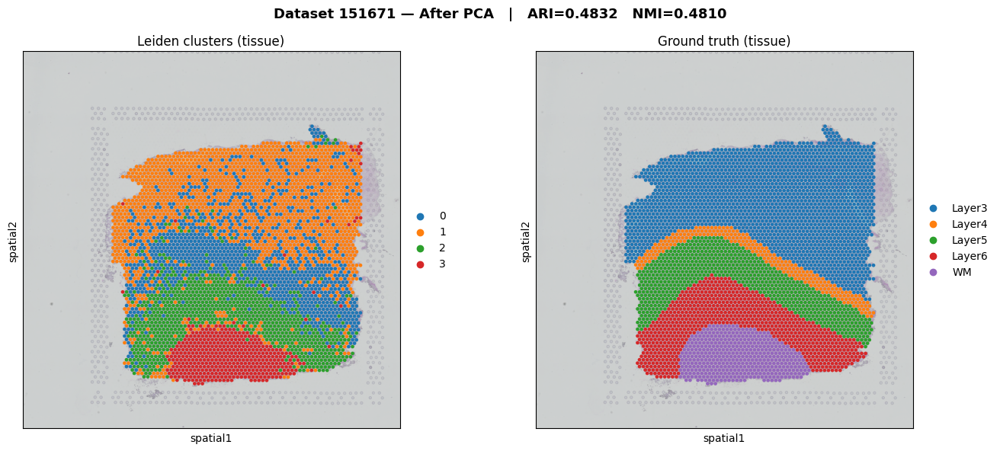

  Saved → 151671_After_PCA.png

  ── Top 2000 features ──
     ARI=0.3196  NMI=0.4067


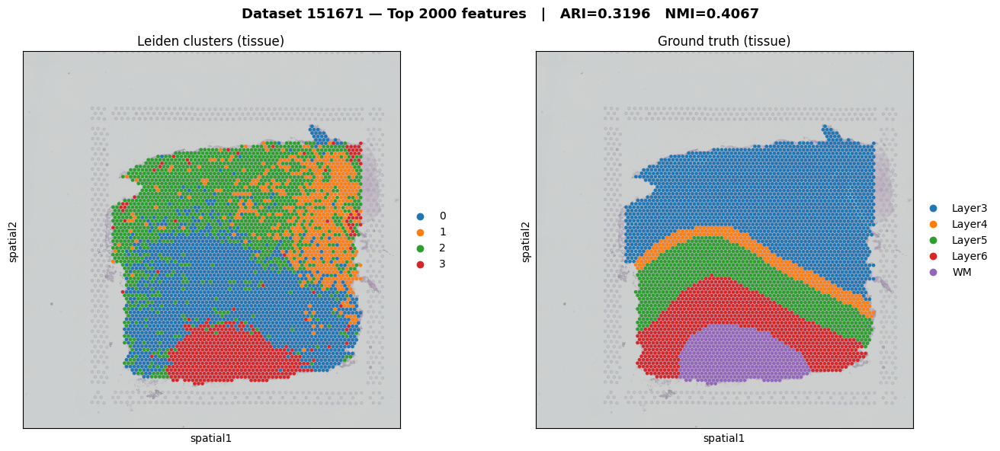

  Saved → 151671_Top_2000_features.png

  ── Top 5000 features ──
     ARI=0.3993  NMI=0.4879


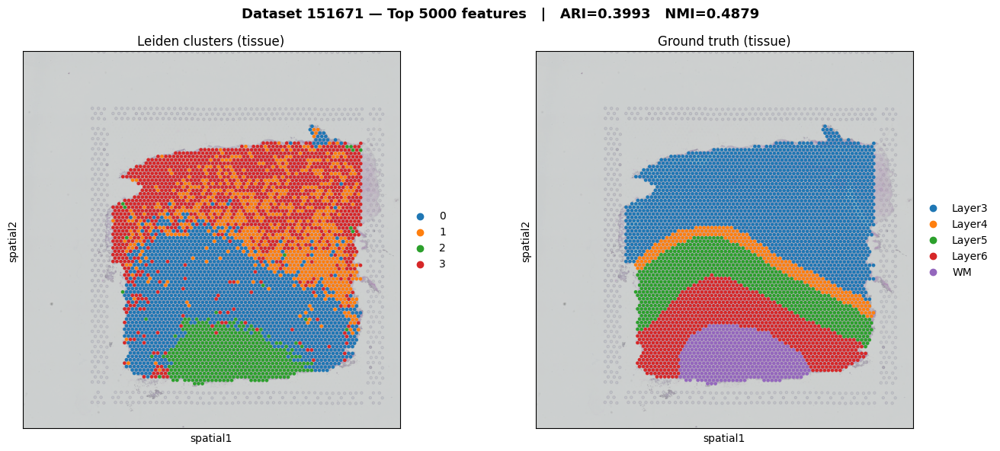

  Saved → 151671_Top_5000_features.png

═══════════════════════════════════════════════════════
  Dataset : 151507
═══════════════════════════════════════════════════════


/usr/local/lib/python3.12/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


  [151507] spots=4221  genes=33538

  ── After PCA ──
     ARI=0.2683  NMI=0.3996


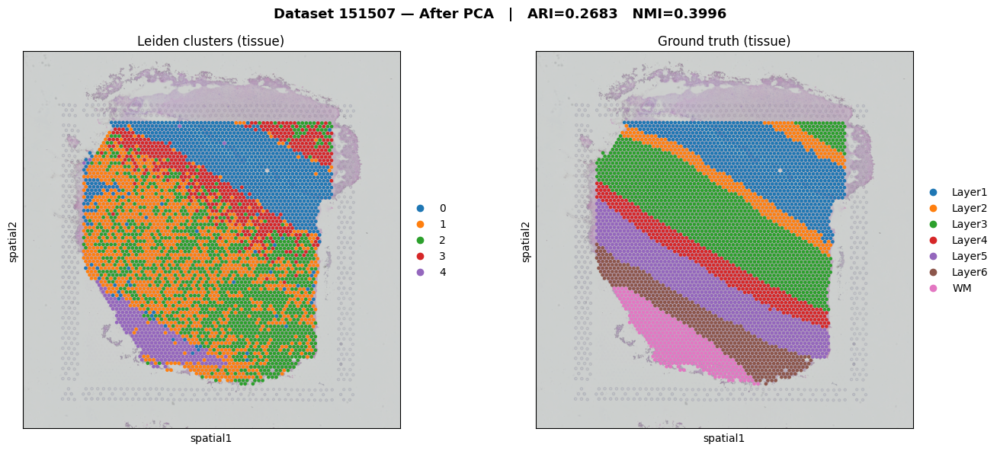

  Saved → 151507_After_PCA.png

  ── Top 2000 features ──
     ARI=0.2453  NMI=0.3530


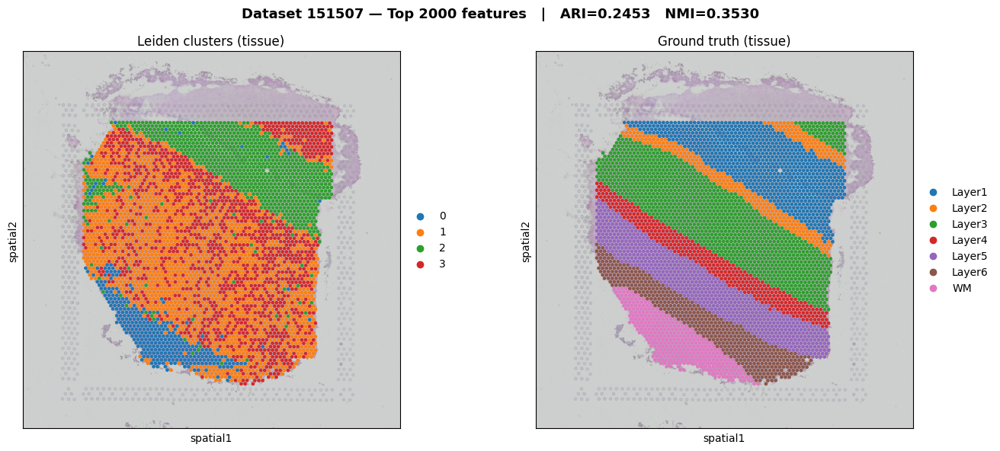

  Saved → 151507_Top_2000_features.png

  ── Top 5000 features ──
     ARI=0.2358  NMI=0.3192


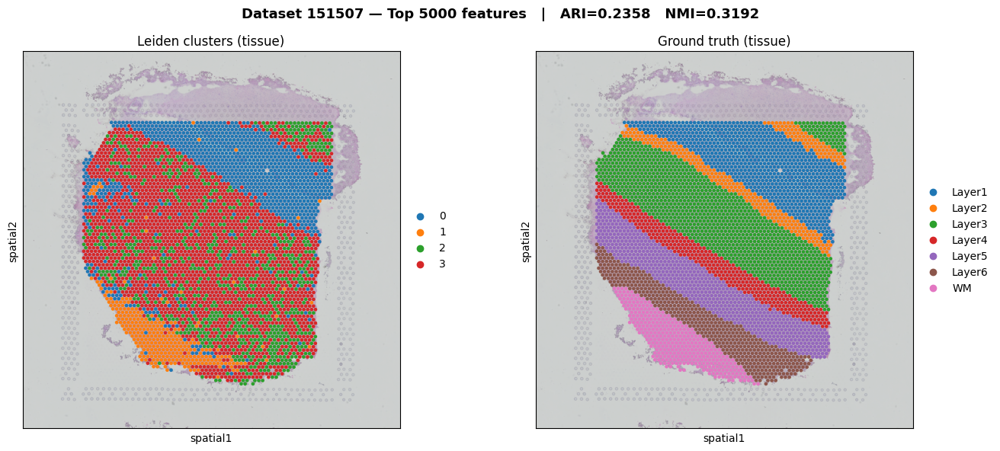

  Saved → 151507_Top_5000_features.png

═══════════════════════════════════════════════════════
  Dataset : 151508
═══════════════════════════════════════════════════════


/usr/local/lib/python3.12/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


  [151508] spots=4381  genes=33538

  ── After PCA ──
     ARI=0.2601  NMI=0.3613


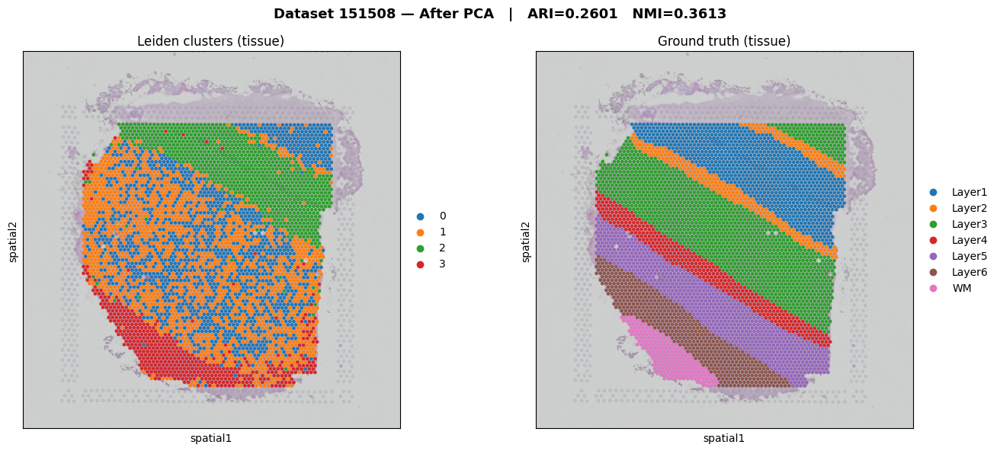

  Saved → 151508_After_PCA.png

  ── Top 2000 features ──
     ARI=0.3253  NMI=0.4146


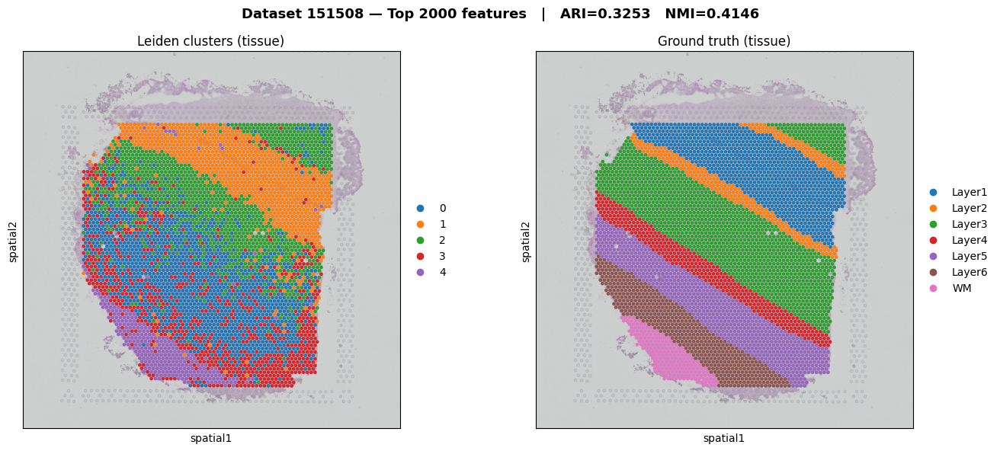

  Saved → 151508_Top_2000_features.png

  ── Top 5000 features ──
     ARI=0.2515  NMI=0.3647


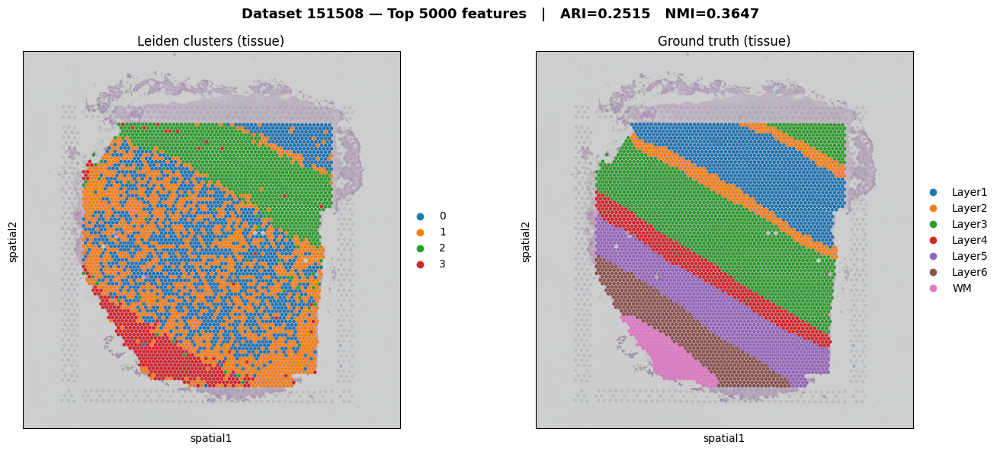

  Saved → 151508_Top_5000_features.png

═══════════════════════════════════════════════════════
  Dataset : 151509
═══════════════════════════════════════════════════════


/usr/local/lib/python3.12/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


  [151509] spots=4788  genes=33538

  ── After PCA ──
     ARI=0.3972  NMI=0.4715


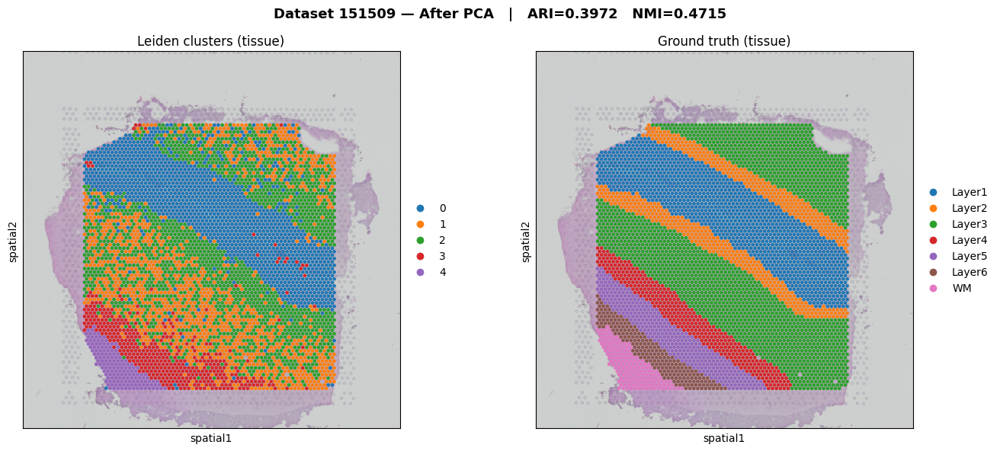

  Saved → 151509_After_PCA.png

  ── Top 2000 features ──
     ARI=0.3784  NMI=0.4542


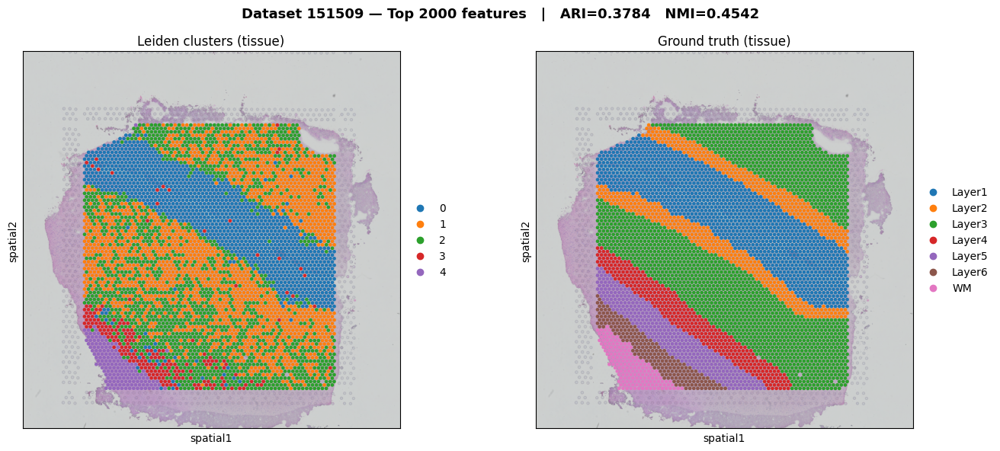

  Saved → 151509_Top_2000_features.png

  ── Top 5000 features ──
     ARI=0.3969  NMI=0.4807


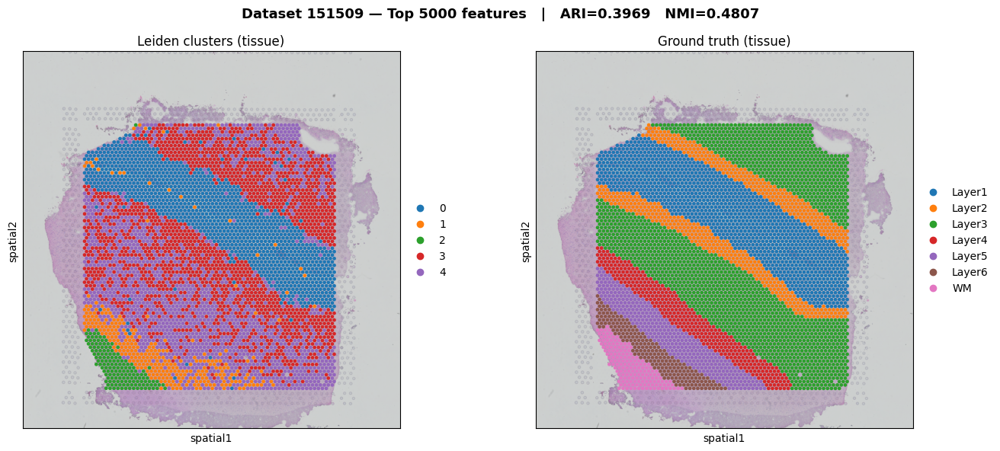

  Saved → 151509_Top_5000_features.png

═══════════════════════════════════════════════════════
  Dataset : 151510
═══════════════════════════════════════════════════════


/usr/local/lib/python3.12/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


  [151510] spots=4595  genes=33538

  ── After PCA ──
     ARI=0.3050  NMI=0.3733


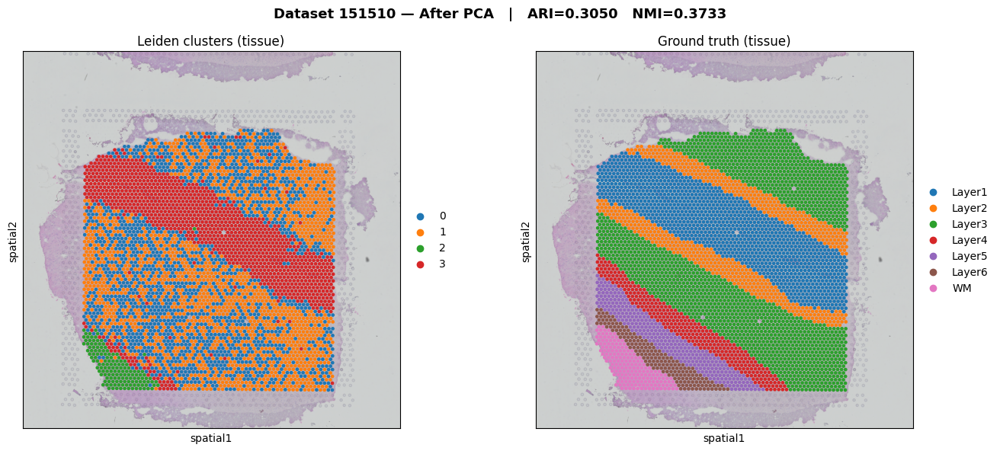

  Saved → 151510_After_PCA.png

  ── Top 2000 features ──
     ARI=0.3181  NMI=0.3888


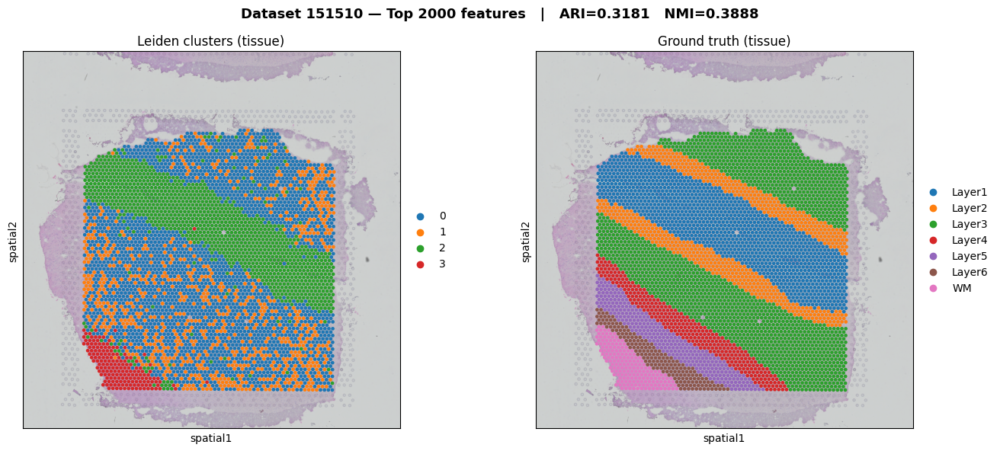

  Saved → 151510_Top_2000_features.png

  ── Top 5000 features ──
     ARI=0.2922  NMI=0.3636


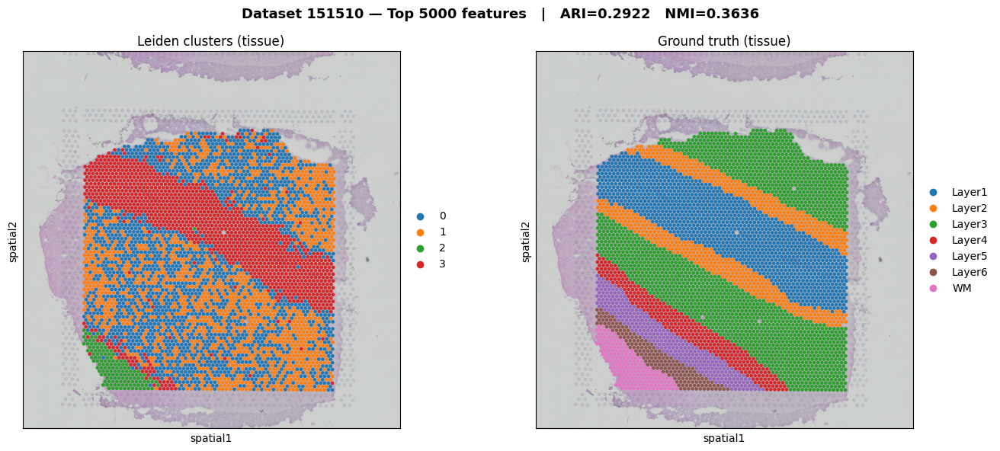

  Saved → 151510_Top_5000_features.png


=== TASK 3 — FINAL RESULTS TABLE ===

        After PCA         Top 2000 features         Top 5000 features        
              ARI     NMI               ARI     NMI               ARI     NMI
dataset                                                                      
151671     0.4832  0.4810            0.3196  0.4067            0.3993  0.4879
151507     0.2683  0.3996            0.2453  0.3530            0.2358  0.3192
151508     0.2601  0.3613            0.3253  0.4146            0.2515  0.3647
151509     0.3972  0.4715            0.3784  0.4542            0.3969  0.4807
151510     0.3050  0.3733            0.3181  0.3888            0.2922  0.3636

Table saved → /content/drive/MyDrive/visium_sample/task3_results/task3_results_table.csv


In [ ]:
"""
Task 3 — Multi-dataset clustering with 3 conditions
Datasets: 151671, 151507, 151508, 151509, 151510
Conditions: After PCA | Top 2000 HVG | Top 5000 HVG
"""

!pip install -q leidenalg python-igraph scikit-misc squidpy

import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import json
import os
import warnings
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

warnings.filterwarnings("ignore", message="zero-centering")
warnings.filterwarnings("ignore", category=FutureWarning)


BASE_PATH = "/content/drive/MyDrive/visium_sample/28200299/10X Visium/DLPFC"
SAVE_DIR  = "/content/drive/MyDrive/visium_sample/task3_results"
os.makedirs(SAVE_DIR, exist_ok=True)

DATASETS  = ["151671", "151507", "151508", "151509", "151510"]

def attach_image(ad, library_id, hires_img, scalefactors):
    if "spatial" not in ad.uns:
        ad.uns["spatial"] = {}
    if library_id not in ad.uns["spatial"]:
        ad.uns["spatial"][library_id] = {"images": {}, "scalefactors": {}}
    ad.uns["spatial"][library_id]["images"]["hires"] = hires_img
    ad.uns["spatial"][library_id]["scalefactors"]    = scalefactors


def load_dataset(dataset_id):
    """
    Load raw AnnData for a given dataset ID.
    Expected folder structure per dataset:
      BASE_PATH/
        {dataset_id}/
          filtered_feature_bc_matrix.h5
          metadata.tsv                      ← may be named differently
          spatial/
            tissue_positions_list.csv
            scalefactors_json.json
            tissue_hires_image.png
    """
    d        = os.path.join(BASE_PATH, dataset_id)
    h5_path  = os.path.join(d, "filtered_feature_bc_matrix.h5")
    spa_dir  = os.path.join(d, "spatial")

    # ── find metadata file ──────────────────────────────────────
    meta_path = None
    for name in ["metadata.tsv", f"{dataset_id}_metadata.tsv",
                 "annotations.tsv", "meta_data.tsv"]:
        candidate = os.path.join(d, name)
        if os.path.exists(candidate):
            meta_path = candidate
            break
    if meta_path is None:
        raise FileNotFoundError(f"No metadata file found in {d}")

    # ── gene expression ─────────────────────────────────────────
    adata = sc.read_10x_h5(h5_path)
    adata.var_names_make_unique()

    # ── spatial coordinates ─────────────────────────────────────
    pos_file = os.path.join(spa_dir, "tissue_positions_list.csv")
    positions = pd.read_csv(
        pos_file, header=None,
        names=["barcode","in_tissue","array_row","array_col",
               "pxl_row_in_fullres","pxl_col_in_fullres"],
        index_col=0
    )
    positions = positions[positions["in_tissue"] == 1]
    adata     = adata[adata.obs_names.isin(positions.index)].copy()
    positions = positions.loc[adata.obs_names]

    adata.obsm["spatial"] = positions[
        ["pxl_col_in_fullres","pxl_row_in_fullres"]
    ].values.astype(float)
    adata.obs["array_row"] = positions["array_row"].values
    adata.obs["array_col"] = positions["array_col"].values

    # ── scale factors + hires image ─────────────────────────────
    with open(os.path.join(spa_dir, "scalefactors_json.json")) as f:
        scalefactors = json.load(f)
    hires_img = mpimg.imread(os.path.join(spa_dir, "tissue_hires_image.png"))

    adata.uns["spatial"] = {
        dataset_id: {
            "images"      : {"hires": hires_img},
            "scalefactors": scalefactors,
        }
    }

    # ── ground truth annotations ─────────────────────────────────
    meta = pd.read_csv(meta_path, sep="\t", index_col=0)
    meta = meta.reindex(adata.obs_names)
    adata.obs["layer_guess_reordered"] = (
        meta["layer_guess_reordered"].astype("category").values
    )

    # drop unlabelled spots
    adata = adata[adata.obs["layer_guess_reordered"].notna()].copy()
    attach_image(adata, dataset_id, hires_img, scalefactors)

    print(f"  [{dataset_id}] spots={adata.n_obs}  genes={adata.n_vars}")
    return adata, hires_img, scalefactors


def run_condition(adata_raw, dataset_id, hires_img, scalefactors,
                  condition, n_hvg=None):
    """
    Run one condition on a dataset and return (ari, nmi, adata_clustered).

    condition : "pca"  | "hvg"
    n_hvg     : None (pca) | 2000 | 5000
    """
    ad = adata_raw.copy()
    attach_image(ad, dataset_id, hires_img, scalefactors)

    if condition == "hvg":
        # HVG selection on RAW counts (seurat_v3 requirement)
        sc.pp.highly_variable_genes(
            ad, n_top_genes=n_hvg,
            flavor="seurat_v3", subset=True
        )

    # normalize → log1p → scale → PCA → neighbors → Leiden
    sc.pp.normalize_total(ad, target_sum=1e4)
    sc.pp.log1p(ad)
    sc.pp.scale(ad, max_value=10)
    sc.tl.pca(ad, n_comps=50)
    sc.pp.neighbors(ad, n_neighbors=15, n_pcs=30)
    sc.tl.umap(ad)

    cluster_key = f"leiden_{condition}" if condition == "pca" else f"leiden_hvg{n_hvg}"
    sc.tl.leiden(
        ad, resolution=0.5,
        key_added=cluster_key,
        flavor="igraph", n_iterations=2, directed=False
    )

    true = ad.obs["layer_guess_reordered"].astype(str).values
    pred = ad.obs[cluster_key].astype(str).values
    ari  = adjusted_rand_score(true, pred)
    nmi  = normalized_mutual_info_score(true, pred)

    return ari, nmi, ad, cluster_key


def save_spatial_plot(ad, cluster_key, dataset_id, condition_label,
                      ari, nmi, save_dir):
    """2-panel spatial plot: Leiden clusters | Ground truth on tissue."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(
        f"Dataset {dataset_id} — {condition_label}"
        f"   |   ARI={ari:.4f}   NMI={nmi:.4f}",
        fontsize=13, fontweight="bold"
    )

    sq.pl.spatial_scatter(
        ad, color=cluster_key,
        library_id=dataset_id,
        img=True, img_alpha=0.6,
        size=1.3, ax=axes[0],
        title="Leiden clusters (tissue)"
    )
    sq.pl.spatial_scatter(
        ad, color="layer_guess_reordered",
        library_id=dataset_id,
        img=True, img_alpha=0.6,
        size=1.3, ax=axes[1],
        title="Ground truth (tissue)"
    )

    plt.tight_layout()
    fname = f"{dataset_id}_{condition_label.replace(' ','_')}.png"
    plt.savefig(os.path.join(save_dir, fname), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"  Saved → {fname}")



CONDITIONS = [
    ("pca",  None, "After PCA"),
    ("hvg",  2000, "Top 2000 features"),
    ("hvg",  5000, "Top 5000 features"),
]

# results[dataset_id] = {"After PCA": (ari, nmi), "Top 2000 ...": ..., ...}
results = {}

plt.ioff()

for ds_id in DATASETS:
    print(f"\n{'═'*55}")
    print(f"  Dataset : {ds_id}")
    print(f"{'═'*55}")

    try:
        adata_raw, hires_img, scalefactors = load_dataset(ds_id)
    except Exception as e:
        print(f"  ✗ Failed to load {ds_id}: {e}")
        results[ds_id] = {label: (float("nan"), float("nan"))
                          for _, _, label in CONDITIONS}
        continue

    results[ds_id] = {}

    for cond, n_hvg, label in CONDITIONS:
        print(f"\n  ── {label} ──")
        try:
            ari, nmi, ad_clustered, cluster_key = run_condition(
                adata_raw, ds_id, hires_img, scalefactors, cond, n_hvg
            )
            print(f"     ARI={ari:.4f}  NMI={nmi:.4f}")
            results[ds_id][label] = (ari, nmi)

            save_spatial_plot(
                ad_clustered, cluster_key,
                ds_id, label, ari, nmi, SAVE_DIR
            )
        except Exception as e:
            print(f"  ✗ Condition '{label}' failed: {e}")
            results[ds_id][label] = (float("nan"), float("nan"))

plt.ion()

rows = []
for ds_id in DATASETS:
    row = {"dataset": ds_id}
    for _, _, label in CONDITIONS:
        ari, nmi = results[ds_id].get(label, (float("nan"), float("nan")))
        short = label.replace("After ","").replace("Top ","").replace(" features","")
        row[f"ARI_{short}"] = round(ari, 4)
        row[f"NMI_{short}"] = round(nmi, 4)
    rows.append(row)

df = pd.DataFrame(rows).set_index("dataset")

col_order = [
    "ARI_PCA", "NMI_PCA",
    "ARI_2000", "NMI_2000",
    "ARI_5000", "NMI_5000",
]
df = df[col_order]
df.columns = pd.MultiIndex.from_tuples([
    ("After PCA",         "ARI"), ("After PCA",         "NMI"),
    ("Top 2000 features", "ARI"), ("Top 2000 features", "NMI"),
    ("Top 5000 features", "ARI"), ("Top 5000 features", "NMI"),
])

print("\n\n=== TASK 3 — FINAL RESULTS TABLE ===\n")
print(df.to_string())

csv_path = os.path.join(SAVE_DIR, "task3_results_table.csv")
df.to_csv(csv_path)
print(f"\nTable saved → {csv_path}")